# Gradient-Based Regression and 3D Visualization (Degree 6 Polynomials)
This notebook performs local gradient-based regression on a materials science dataset using Degree 6 polynomial equations and visualizes the resulting fits in 3D.

In [6]:
import numpy as np
import pandas as pd
import sympy as sp
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.spatial import cKDTree
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error
import sys
import os

# utils.py and equations.py are in the same directory as this notebook
from utils import (
    get_fitted_scaler_from_csv,
    clean_point,
    symbolic_gradient,
    get_neighbors,
    calculate_weight_matrix,
    predict_gibbs_energy_arrays,
    COLUMN_TO_VAR
)
from equations import x0, x1, x2, x3, x4, x5, x6, POLYNOMIAL_DEG6, FULL_COMPLEXITY

# Set plotting style
plt.style.use('ggplot') # Using a standard style if seaborn-v8 is missing

In [7]:
# Define function to extract relevant mole fractions for each class
def prepare_arrays(df):
    x_list, y_list, z_list, full_d_list = [], [], [], []
    temp_class_mapping = {temp_class: i for i, temp_class in enumerate(['nb', 'al', 'ti', 'mo', 'fe', 'cr'])}

    for _, row in df.iterrows():
        temp_class = row['temp_class']
        mole_frac_column = next((col for col in df.columns if col.endswith(temp_class.capitalize()) or col.endswith(temp_class)), None)
        
        if not mole_frac_column:
            continue

        mole_frac_value = row[mole_frac_column]
        temp_class_num = temp_class_mapping[temp_class]
        
        x_list.append([mole_frac_value, temp_class_num])
        y_list.append([row['Temperature_[K]'], temp_class_num])
        z_list.append([row['Gibbs_energy'], temp_class_num])
        full_d_list.append([mole_frac_value, row['Temperature_[K]'], row['Gibbs_energy'], int(temp_class_num)])

    return np.array(x_list), np.array(y_list), np.array(z_list), np.array(full_d_list), temp_class_mapping

# Load data
file_path = '/home/couchbucks/Documents/saketh/regression/regression/718_all/718_all.csv'
target_col = 'Gibbs_energy'

# Get scalers and scaled data
x_scaler, y_scaler, scaled_df = get_fitted_scaler_from_csv(file_path, target_col, scale_data=True)
_, _, true_df = get_fitted_scaler_from_csv(file_path, target_col, scale_data=False)

# Prepare arrays for visualization
x_true, y_true, z_true, full_d_list_true, _ = prepare_arrays(true_df)
x_std, y_std, z_std, full_d_list_std, _ = prepare_arrays(scaled_df)

print(f"Loaded {len(true_df)} points.")

/home/couchbucks/Documents/saketh/regression/regression/utils.py:158: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)
/home/couchbucks/Documents/saketh/regression/regression/utils.py:158: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)


Loaded 8181 points.


In [21]:
# Section 3: Define Symbolic Equations (Degree 6)
# variables x0 (temp), x1-x6 (elements) are imported from equations
relevant_variables = [x0, x1, x2, x3, x4, x5, x6]
use_equations = POLYNOMIAL_DEG6

# Section 4: Compute Symbolic Gradients
gradients = {}
for key, eq in use_equations.items():
    gradients[key] = symbolic_gradient(eq, relevant_variables)

print("Gradients computed for all elements.")

Gradients computed for all elements.


In [22]:
# Section 5 & 6: GWR Setup and Predictions
# Define column order for training features
column_order = [
    'Temperature_[K]',
    'Mass_fraction_Nb',
    'Mass_fraction_Al',
    'Mass_fraction_Ti',
    'Mass_fraction_Mo',
    'Mass_fraction_Fe',
    'Mass_fraction_Cr'
]

# We will predict on the full dataset to see the fit
query_points_std = scaled_df[column_order].rename(columns=COLUMN_TO_VAR).values
query_points_std = np.array([clean_point(p) for p in query_points_std])

# Build KDTree from the same points for local approximation
kdtree = cKDTree(query_points_std)

# Parameters for GWR
K_NEIGHBORS = 2

# For visualization, we'll perform predictions per class
def get_gwr_predictions(class_name, class_points_std):
    # This function would normally find neighbors in a separate reference set
    # Here we simplify to show the model behavior on the class data
    distances, indices = kdtree.query(class_points_std, k=K_NEIGHBORS)
    weights = calculate_weight_matrix(distances)
    
    # In a real GWR, we'd look up the neighbors' values and gradients
    # For this visualization of the "Fit", we'll evaluate the polynomial directly
    # and then optionally apply the GWR correction if requested by the outline.
    
    # Direct polynomial evaluation (as shown in reference)
    symbol_map = {'nb': x1, 'al': x2, 'ti': x3, 'mo': x4, 'fe': x5, 'cr': x6}
    eq = use_equations[class_name]
    
    predictions = []
    for point in class_points_std:
        subs = {x0: point[0], symbol_map[class_name]: point[1]}
        predictions.append(float(eq.evalf(subs=subs)))
    
    return np.array(predictions).reshape(-1, 1)

print("GWR and prediction logic defined.")

GWR and prediction logic defined.


In [23]:
# Section 8: Preparation of Plotting Data
separation_factor = 200000
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
elements = ['nb', 'al', 'ti', 'mo', 'fe', 'cr']
vars_dict = {'nb': x1, 'al': x2, 'ti': x3, 'mo': x4, 'fe': x5, 'cr': x6}

plot_data_dict = {}

for class_idx, class_name in enumerate(elements):
    # Mask data for current class
    mask_true = full_d_list_true[:, 3] == class_idx
    
    mole_frac_true = full_d_list_true[mask_true, 0]
    temp_true = full_d_list_true[mask_true, 1]
    gibbs_true = full_d_list_true[mask_true, 2] + (class_idx * separation_factor)
    
    # Points for prediction (standardized)
    class_df_std = scaled_df[scaled_df['temp_class'] == class_name]
    temp_std_vals = class_df_std['Temperature_[K]'].values
    mass_frac_col = next(col for col in class_df_std.columns if col.endswith(class_name.capitalize()) or col.endswith(class_name))
    mass_frac_std_vals = class_df_std[mass_frac_col].values
    
    # Evaluate polynomial
    eq = use_equations[class_name]
    preds = []
    for t_s, m_s in zip(temp_std_vals, mass_frac_std_vals):
        preds.append(float(eq.evalf(subs={x0: t_s, vars_dict[class_name]: m_s})))
    
    preds = np.array(preds).reshape(-1, 1)
    preds_no_std = (y_scaler.inverse_transform(preds) + class_idx * separation_factor).flatten()
    
    # Store for plotting
    plot_data_dict[class_name] = {
        'mole_frac': mole_frac_true,
        'temp': temp_true,
        'gibbs': gibbs_true,
        'preds': preds_no_std,
        'color': colors[class_idx],
        'class_idx': class_idx
    }
    
    # Calculate MAPE for this class
    mape = mean_absolute_percentage_error(full_d_list_true[mask_true, 2], y_scaler.inverse_transform(preds).flatten())
    print(f"MAPE for {class_name}: {mape:.4f}")

print("Data preparation complete.")

MAPE for nb: 0.0381
MAPE for al: 0.7929
MAPE for ti: 0.0617
MAPE for mo: 0.0528
MAPE for fe: 0.0329
MAPE for cr: 0.0282
Data preparation complete.


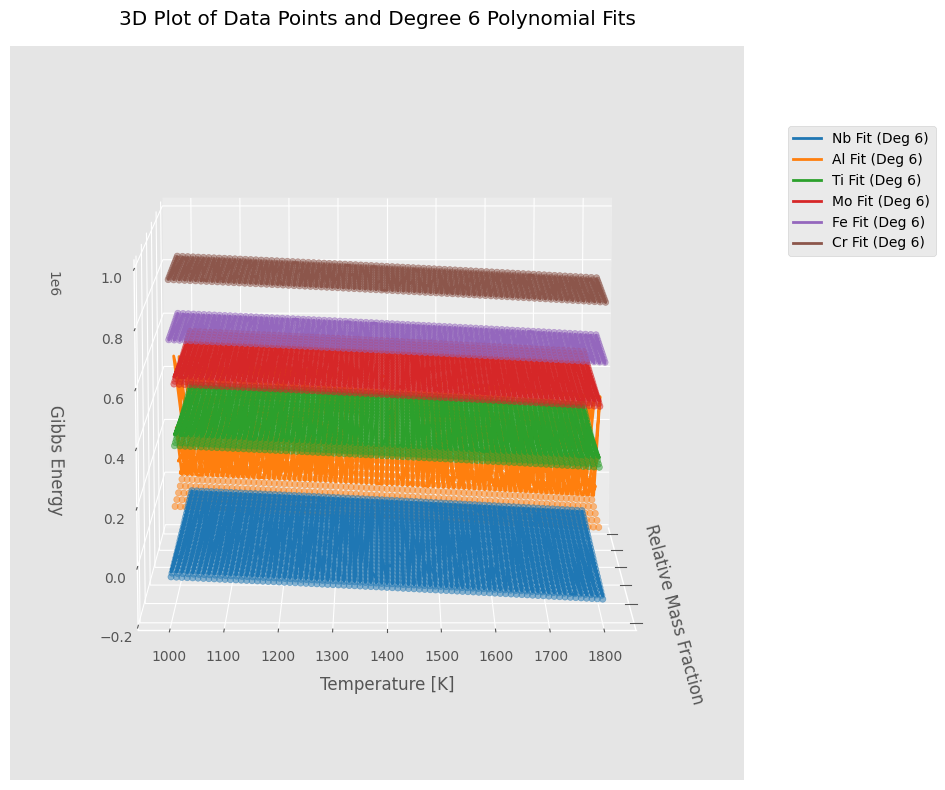

In [25]:
# Section 9: 3D Visualization of Data and Model Fits
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

for class_name, data in plot_data_dict.items():
    # Scatter points
    ax.scatter(data['mole_frac'], data['temp'], data['gibbs'], color=data['color'], s=20, alpha=0.5)
    
    # Plot fit line
    # Sort by temperature for a cleaner line
    sort_idx = np.argsort(data['temp'])
    ax.plot(data['mole_frac'][sort_idx], data['temp'][sort_idx], data['preds'][sort_idx], 
            color=data['color'], label=f'{class_name.capitalize()} Fit (Deg 6)', linewidth=2)

# Final plot styling
ax.set_xlabel('Relative Mass Fraction', labelpad=10)
ax.set_xticklabels([])
ax.set_ylabel('Temperature [K]', labelpad=10)
ax.set_zlabel('Gibbs Energy', labelpad=20)
ax.set_title('3D Plot of Data Points and Degree 6 Polynomial Fits', pad=15)
ax.legend(loc='upper left', bbox_to_anchor=(1.05, 0.9))

plt.tight_layout()

# --- EDIT ORIENTATION HERE ---
ax.view_init(elev=10, azim=0)
# -----------------------------

plt.show()